# Laboratorio Semana 10 — DBSCAN y Clustering Jerárquico
## Comparación de Modelos de Clustering en Proyectos de Inversión Pública

**Integrantes (Data Hunters):** Fernando Torres, Romy Tipacti, Arturo Alvarez  
**Base de datos:** `matriz_analitica_final.csv`

---

En esta tarea evaluamos dos alternativas a K-means sobre nuestro portafolio de proyectos de inversión pública:
1. **DBSCAN:** para agrupar por densidad y separar proyectos atípicos como ruido (`-1`) sin asumir formas esféricas.
2. **Clustering Jerárquico Aglomerativo:** para analizar la estructura de fusiones en un dendrograma y comparar criterios de enlace (`ward`, `complete`, `average`, `single`).

Trabajamos sobre la misma matriz analítica y con las mismas 12 variables cuantitativas que preparamos para K-means en la Tarea 2, sin incluir `cluster_kmeans` en el cálculo de distancias para poder comparar las soluciones de forma independiente.


In [1]:
# Importamos librerías para manejo de datos, modelos y gráficos
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Configuración básica de visualización
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: "%.2f" % x)


## 1. Carga de datos y matriz estandarizada

Leemos la matriz analítica final y seleccionamos las 12 variables con las que venimos trabajando (avance físico, gasto, contratos, tiempo y dummies de gobierno). Luego estandarizamos con `StandardScaler` para que todas las variables tengan media 0 y varianza 1.


In [2]:
import os

# Leemos la matriz analítica final
ruta = "matriz_analitica_final.csv" if os.path.exists("matriz_analitica_final.csv") else "../Entrega_2/matriz_analitica_final.csv"
df = pd.read_csv(ruta)

# Lista de las 12 variables analíticas que usamos para calcular distancias
features = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos",
    "tamano_inversion_ord",
    "gob_GOBIERNOS LOCALES",
    "gob_GOBIERNOS REGIONALES"
]

X = df[features].copy()

# Escalamos con StandardScaler
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

# Creamos una copia para almacenar los resultados de cada modelo
df_resultados = df.copy()

print(f"Dimensiones de la matriz: {df.shape[0]:,} obras × {df.shape[1]} columnas")
print("Cantidad de variables seleccionadas para distancias:", len(features))


Dimensiones de la matriz: 2,067 obras × 17 columnas
Cantidad de variables seleccionadas para distancias: 12


## 2. Guardamos la asignación previa de K-Means (K=4)

Ajustamos K-means con K=4 (usando la misma semilla 42 de la Tarea 2) para tener la columna `cluster_kmeans` en nuestra tabla de resultados.


In [3]:
# Ajustamos K-means con K=4 tal como definimos en la tarea anterior
kmeans = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
df_resultados["cluster_kmeans"] = kmeans.fit_predict(X_std)

print("Distribución de proyectos por cluster en K-means:")
display(df_resultados["cluster_kmeans"].value_counts().sort_index().to_frame("n_proyectos"))


Distribución de proyectos por cluster en K-means:


,n_proyectos
cluster_kmeans,
0,809
1,1
2,924
3,333


## 3. DBSCAN: Clustering basado en densidad

### Elección de `min_samples` inicial
Para datos con varias dimensiones (en nuestro caso 12 variables estandarizadas), una regla práctica habitual es tomar aproximadamente el doble de las dimensiones:
$$\text{min\_samples} \approx 2 \times 12 = 24$$
Usar 24 puntos como vecindad mínima ayuda a que los clusters sean densos y evita que obras aisladas o con ruido formen grupos artificiales.


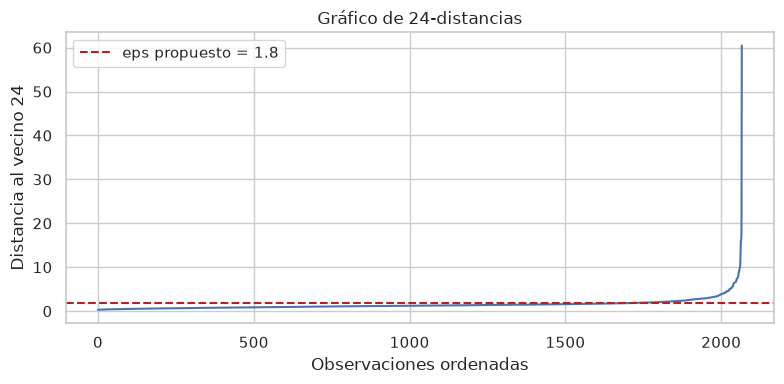

In [4]:
# Calculamos las distancias al vecino 24 para cada punto
min_samples = 24

vecinos = NearestNeighbors(n_neighbors=min_samples)
vecinos.fit(X_std)

distancias, _ = vecinos.kneighbors(X_std)
k_distancias = distancias[:, -1]

# Ordenamos de menor a mayor para buscar el codo
k_distancias = np.sort(k_distancias)
kdist_df = pd.DataFrame({
    "observacion_ordenada": np.arange(len(k_distancias)),
    "k_distancia": k_distancias
})

# Graficamos la curva de 24-distancias
plt.figure(figsize=(8, 4))
ax = sns.lineplot(
    data=kdist_df,
    x="observacion_ordenada",
    y="k_distancia"
)
ax.axhline(1.8, color="firebrick", linestyle="--", label="eps propuesto = 1.8")

ax.set(
    title=f"Gráfico de {min_samples}-distancias",
    xlabel="Observaciones ordenadas",
    ylabel=f"Distancia al vecino {min_samples}"
)
plt.legend()
plt.tight_layout()
plt.show()


### Propuesta de `eps` inicial y prueba de sensibilidad
En el gráfico vemos que la curva sube suavemente hasta ~1.7 y a partir de **1.8** empieza a levantarse con fuerza, disparándose al final por encima de 60 debido a obras gigantescas como la Línea 2 del Metro.

Proponemos **`eps = 1.8`** como punto de partida y probamos valores cercanos (`1.5`, `1.8`, `2.0`, `2.2`) para ver cómo reaccionan los clusters y el ruido.


In [5]:
# Probamos valores cercanos de eps para ver la estabilidad
comparacion_eps = []

for eps in [1.5, 1.8, 2.0, 2.2]:
    modelo = DBSCAN(eps=eps, min_samples=min_samples)
    labels = modelo.fit_predict(X_std)
    
    etiquetas = set(labels)
    # Contamos clusters sin incluir el ruido (-1)
    n_clusters = len(etiquetas) - (1 if -1 in etiquetas else 0)
    porcentaje_ruido = np.mean(labels == -1) * 100
    
    comparacion_eps.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "ruido_%": porcentaje_ruido
    })

comparacion_eps = pd.DataFrame(comparacion_eps)
display(comparacion_eps.round(2))


,eps,n_clusters,ruido_%
0,1.50,3,14.08
1,1.80,3,8.42
2,2.00,3,6.34
3,2.20,2,5.42


### Partición final de DBSCAN
Nos quedamos con **`eps = 1.8`** y `min_samples = 24`:
- Con `eps = 1.5` el ruido era muy alto (14.1%).
- Con `eps = 1.8` encontramos **3 clusters** con un **8.4% de ruido** (174 proyectos atípicos bien aislados).
- Si subimos a `2.2`, dos grupos se fusionan y perdemos detalle (baja a 2 clusters).


In [6]:
# Ajustamos el modelo definitivo de DBSCAN con eps=1.8
eps_elegido = 1.8
dbscan = DBSCAN(eps=eps_elegido, min_samples=min_samples)
labels_dbscan = dbscan.fit_predict(X_std)

# Guardamos las etiquetas en df_resultados
df_resultados["cluster_dbscan"] = labels_dbscan

# Resumimos los resultados
etiquetas_unicas = set(labels_dbscan)
n_clusters_db = len(etiquetas_unicas) - (1 if -1 in etiquetas_unicas else 0)
porcentaje_ruido = np.mean(labels_dbscan == -1) * 100

conteos_db = (
    pd.Series(labels_dbscan, name="cluster")
    .value_counts()
    .sort_index()
)

print("Número de clusters:", n_clusters_db)
print("Porcentaje de ruido:", round(porcentaje_ruido, 1), "%")
print("\nTamaño por etiqueta:")
display(conteos_db.to_frame("n"))


Número de clusters: 3
Porcentaje de ruido: 8.4 %

Tamaño por etiqueta:


,n
cluster,
-1,174
0,501
1,482
2,910


## 4. Clustering jerárquico aglomerativo

### Dendrograma con Ward (Muestra de 50 proyectos)
Como nuestra base tiene **2,067 proyectos**, si intentamos dibujar el dendrograma con todos los datos se forma una masa negra de etiquetas ilegibles.  
Por eso tomamos una **muestra aleatoria de 50 obras** con semilla fija (`random_state=42`) para poder observar claramente las ramas y las alturas de fusión.


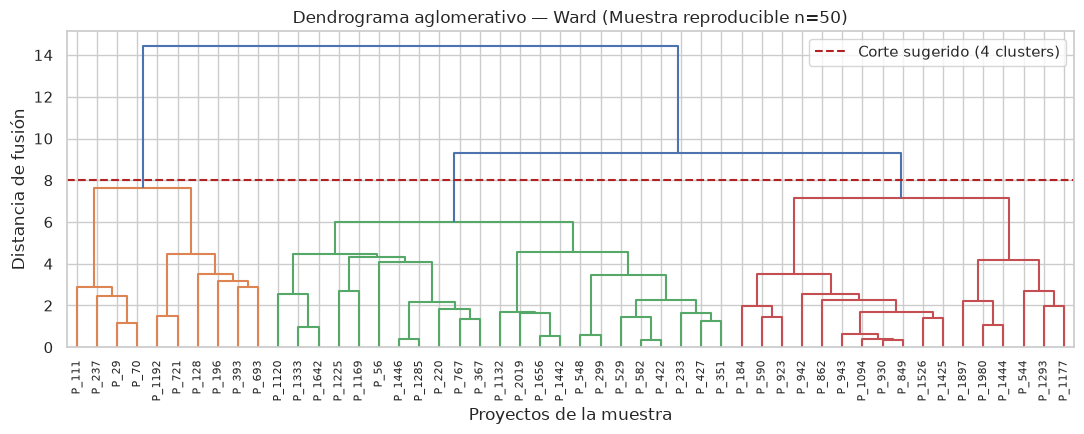

In [7]:
# Construimos el dendrograma con Ward sobre una muestra de 50 proyectos
np.random.seed(42)
indices_muestra = np.random.choice(len(df), size=50, replace=False)
X_muestra_std = X_std[indices_muestra]

Z_ward_muestra = linkage(
    X_muestra_std,
    method="ward"
)

# Graficamos el dendrograma de la muestra
plt.figure(figsize=(11, 4.5))
dendrogram(
    Z_ward_muestra,
    labels=[f"P_{idx}" for idx in indices_muestra],
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=8.0
)
plt.axhline(y=8.0, color="firebrick", linestyle="--", label="Corte sugerido (4 clusters)")
plt.title("Dendrograma aglomerativo — Ward (Muestra reproducible n=50)")
plt.xlabel("Proyectos de la muestra")
plt.ylabel("Distancia de fusión")
plt.legend()
plt.tight_layout()
plt.show()


### Comparación de criterios de enlace
Probamos los 4 criterios de enlace principales (`single`, `complete`, `average` y `ward`) fijando 4 clusters para ver qué tamaño de grupos produce cada uno sobre todo el dataset.


In [8]:
# Guardamos la solución de cada criterio de enlace
resultados_linkage = {}

for metodo in [
    "single",
    "complete",
    "average",
    "ward"
]:
    modelo_h = AgglomerativeClustering(
        n_clusters=4,
        linkage=metodo
    )
    resultados_linkage[metodo] = modelo_h.fit_predict(X_std)

# Comparamos el tamaño de los clusters producidos por cada enlace
resumen_linkage = []

for metodo, etiquetas in resultados_linkage.items():
    conteos = pd.Series(etiquetas).value_counts()
    resumen_linkage.append({
        "linkage": metodo,
        "n_clusters": len(conteos),
        "tamaño_min": conteos.min(),
        "tamaño_max": conteos.max()
    })

resumen_linkage = pd.DataFrame(resumen_linkage)
display(resumen_linkage)


,linkage,n_clusters,tamaño_min,tamaño_max
0,single,4,1,2062
1,complete,4,1,2053
2,average,4,1,2054
3,ward,4,1,1117


### Partición final con Ward
En la tabla se ve que:
- `single`, `complete` y `average` fallan en nuestros datos porque meten más de 2,050 obras en un solo cluster gigante y dejan 3 clusters casi vacíos (1 o 3 proyectos), debido a que los outliers y proyectos grandes jalan las distancias (efecto de encadenamiento).
- **`Ward`** es el único criterio equilibrado, ya que minimiza la varianza interna y forma grupos consistentes. Por tanto, elegimos **Ward con K = 4**.


In [9]:
# Ajustamos el modelo jerárquico definitivo con Ward y K=4
modelo_hier = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

labels_hier = modelo_hier.fit_predict(X_std)

# Guardamos las etiquetas en df_resultados
df_resultados["cluster_hier"] = labels_hier

# Mostramos el tamaño de cada cluster
tamanos_hier = (
    pd.Series(labels_hier, name="cluster")
    .value_counts()
    .sort_index()
)
display(tamanos_hier.to_frame("n"))


,n
cluster,
0,405
1,1117
2,544
3,1


## 5. Comparación entre las soluciones obtenidas

Cruzamos las soluciones para observar coincidencias entre los tres algoritmos antes de la conclusión:


In [10]:
# 1. Cruce K-means vs Jerárquico Ward
print("Cruce K-means vs Jerárquico Ward:")
display(pd.crosstab(df_resultados["cluster_kmeans"], df_resultados["cluster_hier"], rownames=["K-means"], colnames=["Jerárquico"]))

# 2. Cruce DBSCAN vs K-means
print("\nCruce DBSCAN vs K-means:")
display(pd.crosstab(df_resultados["cluster_dbscan"], df_resultados["cluster_kmeans"], rownames=["DBSCAN"], colnames=["K-means"]))


Cruce K-means vs Jerárquico Ward:


Jerárquico,0,1,2,3
K-means,,,,
0,143,358,308,0
1,0,0,0,1
2,190,725,9,0
3,72,34,227,0



Cruce DBSCAN vs K-means:


K-means,0,1,2,3
DBSCAN,,,,
-1,21,1,31,121
0,445,0,6,50
1,343,0,0,139
2,0,0,887,23


### Conclusión 

1. K-Means y Jerárquico Ward produjeron agrupamientos muy similares entre sí: ambos aislaron a la Línea 2 del Metro en un cluster individual y separaron las obras locales de las regionales y nacionales según su magnitud de inversión.
2. DBSCAN no fuerza a las obras atípicas a tener un centroide; encontró 3 zonas densas por nivel institucional y mandó un 8.4% a ruido (proyectos con muchos contratos o plazos desbordados).
3. Los enlaces single, complete y average no fueron adecuados para nuestra base: por la asimetría y los megaproyectos colapsaron más de 2,050 obras en un solo grupo por efecto de encadenamiento.
4. La decisión que más influyó en todo el proceso fue el escalamiento con StandardScaler, ya que sin este el costo de inversión en millones absorbía por completo las distancias euclidianas.


In [11]:
# Guardamos la matriz con las 3 etiquetas finales
df_resultados.to_csv("matriz_analitica_con_clusters.csv", index=False)
print("Archivo 'matriz_analitica_con_clusters.csv' guardado con éxito.")
print(f"Dimensiones finales: {df_resultados.shape[0]:,} proyectos × {df_resultados.shape[1]} columnas")

# Mostramos los primeros proyectos con sus etiquetas asignadas
columnas_ver = ["codigo_proyecto", "nombre_proyecto", "costo_inversion", "cluster_kmeans", "cluster_dbscan", "cluster_hier"]
display(df_resultados[columnas_ver].head(5))


Archivo 'matriz_analitica_con_clusters.csv' guardado con éxito.
Dimensiones finales: 2,067 proyectos × 20 columnas


,codigo_proyecto,nombre_proyecto,costo_inversion,cluster_kmeans,cluster_dbscan,cluster_hier
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,263517133.53,3,-1,2
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,269114681.55,3,-1,2
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,189747493.86,3,1,2
3,2015918,PROYECTO VIAL TACNA LA PAZ,293423741.31,3,-1,2
4,2017383,MEJORAMIENTO Y AMPLIACION DE LOS SISTEMAS DE A...,116305035.72,3,1,2
